# PlantSeg Stage 1 — Trainer 5/8: **ConvNeXtV2Tiny**

Trains a single model and saves `result_ConvNeXtV2Tiny.pkl` (+ per-model figures) to `/kaggle/working/s1_results/`.
Run all 8 trainer notebooks (each fits one Kaggle session), then download/collect the 8 `result_*.pkl` files into a Kaggle dataset and run **PlantSeg_S1_aggregate.ipynb** to build the comparison table, ensemble, stats and combined figures.

> Internet **ON** (timm weights download). 384px CNNs — lower `IMG_SIZE_CNN` to 320/256 if OOM.

In [1]:
!pip install -q timm imagehash statsmodels grad-cam
import os, json, math, time, random, warnings, pickle
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision; from torchvision import transforms
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 70.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 102.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inc

In [2]:
# ============ CONFIG ============
MODEL_NAME = "ConvNeXtV2Tiny"      # this notebook trains ONE model
DATA_ROOT = Path("/kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg")   # <-- EDIT to your dataset mount
if not (DATA_ROOT/"Metadata.csv").exists():
    for cand in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (cand/"Metadata.csv").exists(): DATA_ROOT=cand; break
assert (DATA_ROOT/"Metadata.csv").exists(), f"Metadata.csv not under {DATA_ROOT} — edit DATA_ROOT."

OUTDIR = Path("/kaggle/working/s1_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

SCOPE="full"; FRUIT_HOSTS={"Apple","Citrus","Grape","Banana","Peach","Blueberry","Plum","Cherry","Raspberry","Strawberry"}
NUM_EPOCHS=40; PATIENCE=8; LR=3e-4; WEIGHT_DECAY=1e-4; USE_PRETRAINED=True
USE_CLASS_WEIGHTS=True; LABEL_SMOOTHING=0.05; IMG_SIZE_CNN=384
USE_RANDAUG=True; USE_TTA=True; QUICK_SMOKE=False
print("MODEL:", MODEL_NAME, "| DATA_ROOT:", DATA_ROOT)

MODEL: ConvNeXtV2Tiny | DATA_ROOT: /kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg


In [3]:
# ============ DATA INDEX ============
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta["split"]=meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"]=meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
meta["label"]=meta["Disease"]; meta["plant"]=meta["Plant"]
if SCOPE=="fruit": meta=meta[meta["plant"].isin(FRUIT_HOSTS)].reset_index(drop=True)
meta=meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
CLASS_NAMES=sorted(meta["label"].unique().tolist()); NUM_CLASSES=len(CLASS_NAMES)
label2idx={c:i for i,c in enumerate(CLASS_NAMES)}
train_df=meta[meta.split=="train"].reset_index(drop=True)
val_df=meta[meta.split=="val"].reset_index(drop=True)
test_df=meta[meta.split=="test"].reset_index(drop=True)
if QUICK_SMOKE:
    train_df=train_df.groupby("label",group_keys=False).head(8).reset_index(drop=True)
    val_df=val_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    test_df=test_df.groupby("label",group_keys=False).head(4).reset_index(drop=True); NUM_EPOCHS=1
counts=train_df["label"].map(label2idx).value_counts().reindex(range(NUM_CLASSES)).fillna(0)
inv=np.where(counts.values>0,1.0/counts.values,0.0); cw=inv/inv[inv>0].mean()
class_weights=torch.tensor(cw,dtype=torch.float32,device=device)
print(f"classes={NUM_CLASSES} train={len(train_df)} val={len(val_df)} test={len(test_df)}")

classes=115 train=5367 val=846 test=1561


In [4]:
# ============ TRANSFORMS / DATASET ============
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
def make_transforms(sz):
    ops=[transforms.RandomResizedCrop(sz,scale=(0.7,1.0)),transforms.RandomHorizontalFlip(),transforms.RandomVerticalFlip(p=0.2)]
    ops+=[transforms.RandAugment(num_ops=2,magnitude=9)] if USE_RANDAUG else [transforms.RandomRotation(15),transforms.ColorJitter(0.2,0.2,0.2,0.05)]
    ops+=[transforms.ToTensor(),transforms.Normalize(MEAN,STD)]
    if USE_RANDAUG: ops+=[transforms.RandomErasing(p=0.25)]
    ev=transforms.Compose([transforms.Resize((sz,sz)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    return transforms.Compose(ops), ev
class DS(Dataset):
    def __init__(s,d,t): s.df=d.reset_index(drop=True); s.t=t
    def __len__(s): return len(s.df)
    def __getitem__(s,i):
        r=s.df.iloc[i]; return s.t(Image.open(r.filepath).convert("RGB")), label2idx[r.label]

In [5]:
# ============ MODEL ZOO ============
def build_backbone(name, num_classes, pretrained=USE_PRETRAINED):
    if name=="MobileNetV3Large":
        m=torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
        m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,num_classes); return m,IMG_SIZE_CNN,24
    if name=="EfficientNetB0": return timm.create_model("efficientnet_b0",pretrained=pretrained,num_classes=num_classes),IMG_SIZE_CNN,24
    if name=="ResNet50":
        m=torchvision.models.resnet50(weights="IMAGENET1K_V2" if pretrained else None)
        m.fc=nn.Linear(m.fc.in_features,num_classes); return m,IMG_SIZE_CNN,16
    if name=="EfficientNetV2S": return timm.create_model("tf_efficientnetv2_s",pretrained=pretrained,num_classes=num_classes),IMG_SIZE_CNN,12
    if name=="ConvNeXtV2Tiny": return timm.create_model("convnextv2_tiny",pretrained=pretrained,num_classes=num_classes),IMG_SIZE_CNN,16
    if name=="ViTBase16": return timm.create_model("vit_base_patch16_224",pretrained=pretrained,num_classes=num_classes),224,16
    if name=="SwinTiny": return timm.create_model("swin_tiny_patch4_window7_224",pretrained=pretrained,num_classes=num_classes),224,16
    raise ValueError(name)
class _Gated(nn.Module):
    def __init__(s,ba,da,bb,db,nc,gh,hh,dr):
        super().__init__(); s.branch_a=ba; s.branch_b=bb; fused=da+db
        s.gate=nn.Sequential(nn.Linear(fused,gh),nn.ReLU(),nn.Linear(gh,2),nn.Softmax(dim=1))
        s.classifier=nn.Sequential(nn.Linear(fused,hh),nn.ReLU(),nn.Dropout(dr),nn.Linear(hh,nc))
    def forward(s,x):
        fa,fb=s.branch_a(x),s.branch_b(x); g=s.gate(torch.cat([fa,fb],1))
        return s.classifier(torch.cat([fa*g[:,0:1],fb*g[:,1:2]],1))
def GatedFusionLightModel(nc,pretrained=USE_PRETRAINED):
    mb=torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
    da=mb.classifier[0].in_features; mb.classifier=nn.Identity()
    b=timm.create_model("efficientnet_b0",pretrained=pretrained,num_classes=0,global_pool="avg")
    return _Gated(mb,da,b,b.num_features,nc,128,256,0.3)
FUSION_MODELS={"GatedFusionLight":GatedFusionLightModel}

In [6]:
# ============ TRAIN / METRICS ============
def train_one(model_name, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    if model_name in FUSION_MODELS:
        model=FUSION_MODELS[model_name](NUM_CLASSES).to(device); img_size,bs=224,16
    else:
        model,img_size,bs=build_backbone(model_name,NUM_CLASSES); model=model.to(device)
    ttf,etf=make_transforms(img_size)
    tl=DataLoader(DS(train_df,ttf),batch_size=bs,shuffle=True,num_workers=2,pin_memory=True,drop_last=True)
    vl=DataLoader(DS(val_df,etf),batch_size=bs,shuffle=False,num_workers=2,pin_memory=True)
    te=DataLoader(DS(test_df,etf),batch_size=bs,shuffle=False,num_workers=2,pin_memory=True)
    """is_tf=model_name in ("ViTBase16","SwinTiny"); lr=5e-5 if is_tf else LR; warm_ep=3 if is_tf else 2
    pat=10 if is_tf else patience"""
    low_lr = model_name in ("ViTBase16","SwinTiny","ConvNeXtV2Tiny"); lr = 5e-5 if low_lr else LR; warm_ep = 3 if low_lr else 2; pat = 10 if low_lr else patience
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=WEIGHT_DECAY)
    warm=torch.optim.lr_scheduler.LinearLR(opt,start_factor=0.1,total_iters=warm_ep)
    cos=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max(1,num_epochs-warm_ep))
    sch=torch.optim.lr_scheduler.SequentialLR(opt,[warm,cos],milestones=[warm_ep])
    crit=nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None,label_smoothing=LABEL_SMOOTHING)
    scaler=torch.cuda.amp.GradScaler(enabled=device.type=="cuda")
    hist={"train_loss":[],"val_loss":[],"train_acc":[],"val_acc":[]}; best=-1; best_state=None; bad=0
    for ep in range(num_epochs):
        model.train(); run=cor=tot=0
        for x,y in tl:
            x,y=x.to(device),y.to(device); opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"): out=model(x); loss=crit(out,y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run+=loss.item()*x.size(0); cor+=(out.argmax(1)==y).sum().item(); tot+=y.size(0)
        trl,tra=run/tot,cor/tot
        model.eval(); vr=vc=vt=0
        with torch.no_grad():
            for x,y in vl:
                x,y=x.to(device),y.to(device); out=model(x); loss=crit(out,y)
                vr+=loss.item()*x.size(0); vc+=(out.argmax(1)==y).sum().item(); vt+=y.size(0)
        vlo,vac=vr/vt,vc/vt; sch.step()
        for k,v in zip(hist,[trl,vlo,tra,vac]): hist[k].append(v)
        print(f"[{model_name}] ep{ep+1}/{num_epochs} lr={opt.param_groups[0]['lr']:.1e} trL={trl:.3f} vL={vlo:.3f} trA={tra:.3f} vA={vac:.3f}")
        if vac>best+1e-4: best=vac; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}; bad=0
        else:
            bad+=1
            if ep>=warm_ep and bad>=pat: print(f"  early stop @ ep{ep+1}"); break
    model.load_state_dict(best_state); torch.save(best_state, OUTDIR/f"{model_name}_best.pt")
    model.eval(); P=[]; Y=[]; PR=[]
    with torch.no_grad():
        for x,y in te:
            x=x.to(device); lg=model(x)
            if USE_TTA: lg=lg+model(torch.flip(x,dims=[3]))
            p=F.softmax(lg,1).cpu().numpy(); P.extend(p.argmax(1)); Y.extend(y.numpy()); PR.extend(p)
    return model,img_size,hist,np.array(Y),np.array(P),np.array(PR)

def deployment(model,img_size,nw=5,ni=30):
    n=sum(p.numel() for p in model.parameters()); tmp=OUTDIR/"_t.pt"; torch.save(model.state_dict(),tmp)
    sz=os.path.getsize(tmp)/1e6; os.remove(tmp); d=torch.randn(1,3,img_size,img_size)
    def t(dev):
        m=model.to(dev).eval(); dd=d.to(dev)
        with torch.no_grad():
            for _ in range(nw): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            t0=time.time()
            for _ in range(ni): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            return (time.time()-t0)/ni*1000
    lg=t(device) if device.type=="cuda" else np.nan; lc=t(torch.device("cpu")); model.to(device)
    return {"params_M":n/1e6,"checkpoint_size_MB":sz,"latency_cpu_ms":lc,"latency_gpu_ms":lg}

def compute_metrics(y,yp,ypb,n):
    cm=confusion_matrix(y,yp,labels=range(n)); specs=[]
    for i in range(n):
        tn=cm.sum()-cm[i,:].sum()-cm[:,i].sum()+cm[i,i]; fp=cm[:,i].sum()-cm[i,i]
        specs.append(tn/(tn+fp) if (tn+fp)>0 else np.nan)
    present=[c for c in range(n) if (y==c).sum()>0]; aucs=[]
    for c in present:
        try: aucs.append(roc_auc_score((y==c).astype(int),ypb[:,c]))
        except Exception: pass
    return {"accuracy":accuracy_score(y,yp),"balanced_accuracy":balanced_accuracy_score(y,yp),
            "f1_macro":f1_score(y,yp,average="macro"),"f1_weighted":f1_score(y,yp,average="weighted"),
            "precision_macro":precision_score(y,yp,average="macro",zero_division=0),
            "recall_macro":recall_score(y,yp,average="macro",zero_division=0),
            "mcc":matthews_corrcoef(y,yp),"roc_auc_macro":float(np.mean(aucs)) if aucs else np.nan,
            "macro_specificity":float(np.nanmean(specs))}, cm

In [7]:
# ============ RUN THIS MODEL + SAVE RESULT ============
t0=time.time(); model,img_size,hist,Y,P,PR=train_one(MODEL_NAME); train_time=time.time()-t0
metrics,cm=compute_metrics(Y,P,PR,NUM_CLASSES); dep=deployment(model,img_size)
result={"model_name":MODEL_NAME,"history":hist,"y_true":Y,"y_pred":P,"y_prob":PR,
        "metrics":metrics,"cm":cm,"deployment":dep,"img_size":img_size,"train_time_sec":train_time,
        "class_names":CLASS_NAMES}
pickle.dump(result, open(OUTDIR/f"result_{MODEL_NAME}.pkl","wb"))
print("SAVED", OUTDIR/f"result_{MODEL_NAME}.pkl")
print({k:round(v,4) for k,v in metrics.items() if isinstance(v,float)})
print("deployment:", {k:round(v,2) for k,v in dep.items()})

model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

[ConvNeXtV2Tiny] ep1/40 lr=2.0e-05 trL=4.963 vL=4.898 trA=0.030 vA=0.061
[ConvNeXtV2Tiny] ep2/40 lr=3.5e-05 trL=3.952 vL=3.322 trA=0.306 vA=0.493
[ConvNeXtV2Tiny] ep3/40 lr=5.0e-05 trL=2.533 vL=2.411 trA=0.587 vA=0.617
[ConvNeXtV2Tiny] ep4/40 lr=5.0e-05 trL=1.843 vL=2.134 trA=0.699 vA=0.689
[ConvNeXtV2Tiny] ep5/40 lr=5.0e-05 trL=1.472 vL=1.999 trA=0.790 vA=0.723
[ConvNeXtV2Tiny] ep6/40 lr=4.9e-05 trL=1.274 vL=1.959 trA=0.845 vA=0.740
[ConvNeXtV2Tiny] ep7/40 lr=4.9e-05 trL=1.178 vL=1.971 trA=0.879 vA=0.719
[ConvNeXtV2Tiny] ep8/40 lr=4.8e-05 trL=1.105 vL=1.899 trA=0.901 vA=0.762
[ConvNeXtV2Tiny] ep9/40 lr=4.7e-05 trL=1.054 vL=1.918 trA=0.917 vA=0.759
[ConvNeXtV2Tiny] ep10/40 lr=4.6e-05 trL=1.028 vL=1.919 trA=0.931 vA=0.766
[ConvNeXtV2Tiny] ep11/40 lr=4.4e-05 trL=0.993 vL=1.888 trA=0.931 vA=0.767
[ConvNeXtV2Tiny] ep12/40 lr=4.3e-05 trL=0.977 vL=1.920 trA=0.941 vA=0.761
[ConvNeXtV2Tiny] ep13/40 lr=4.2e-05 trL=0.969 vL=1.944 trA=0.946 vA=0.761
[ConvNeXtV2Tiny] ep14/40 lr=4.0e-05 trL=0.956 v

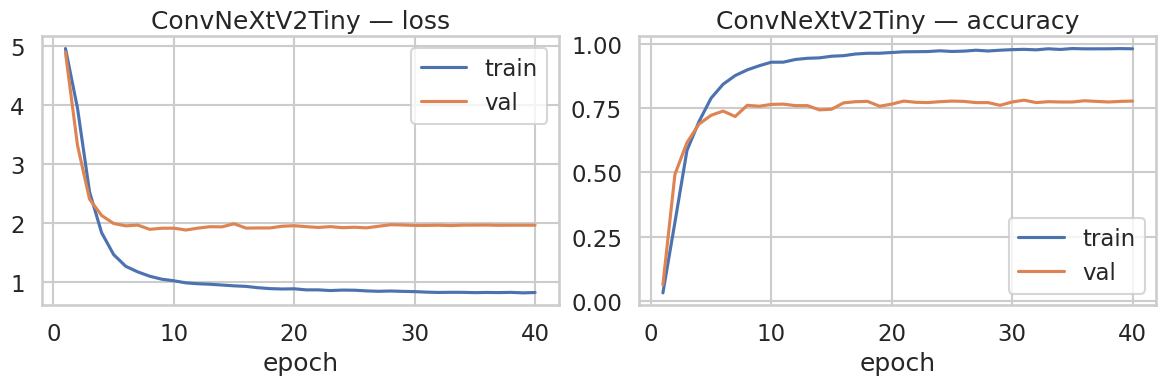

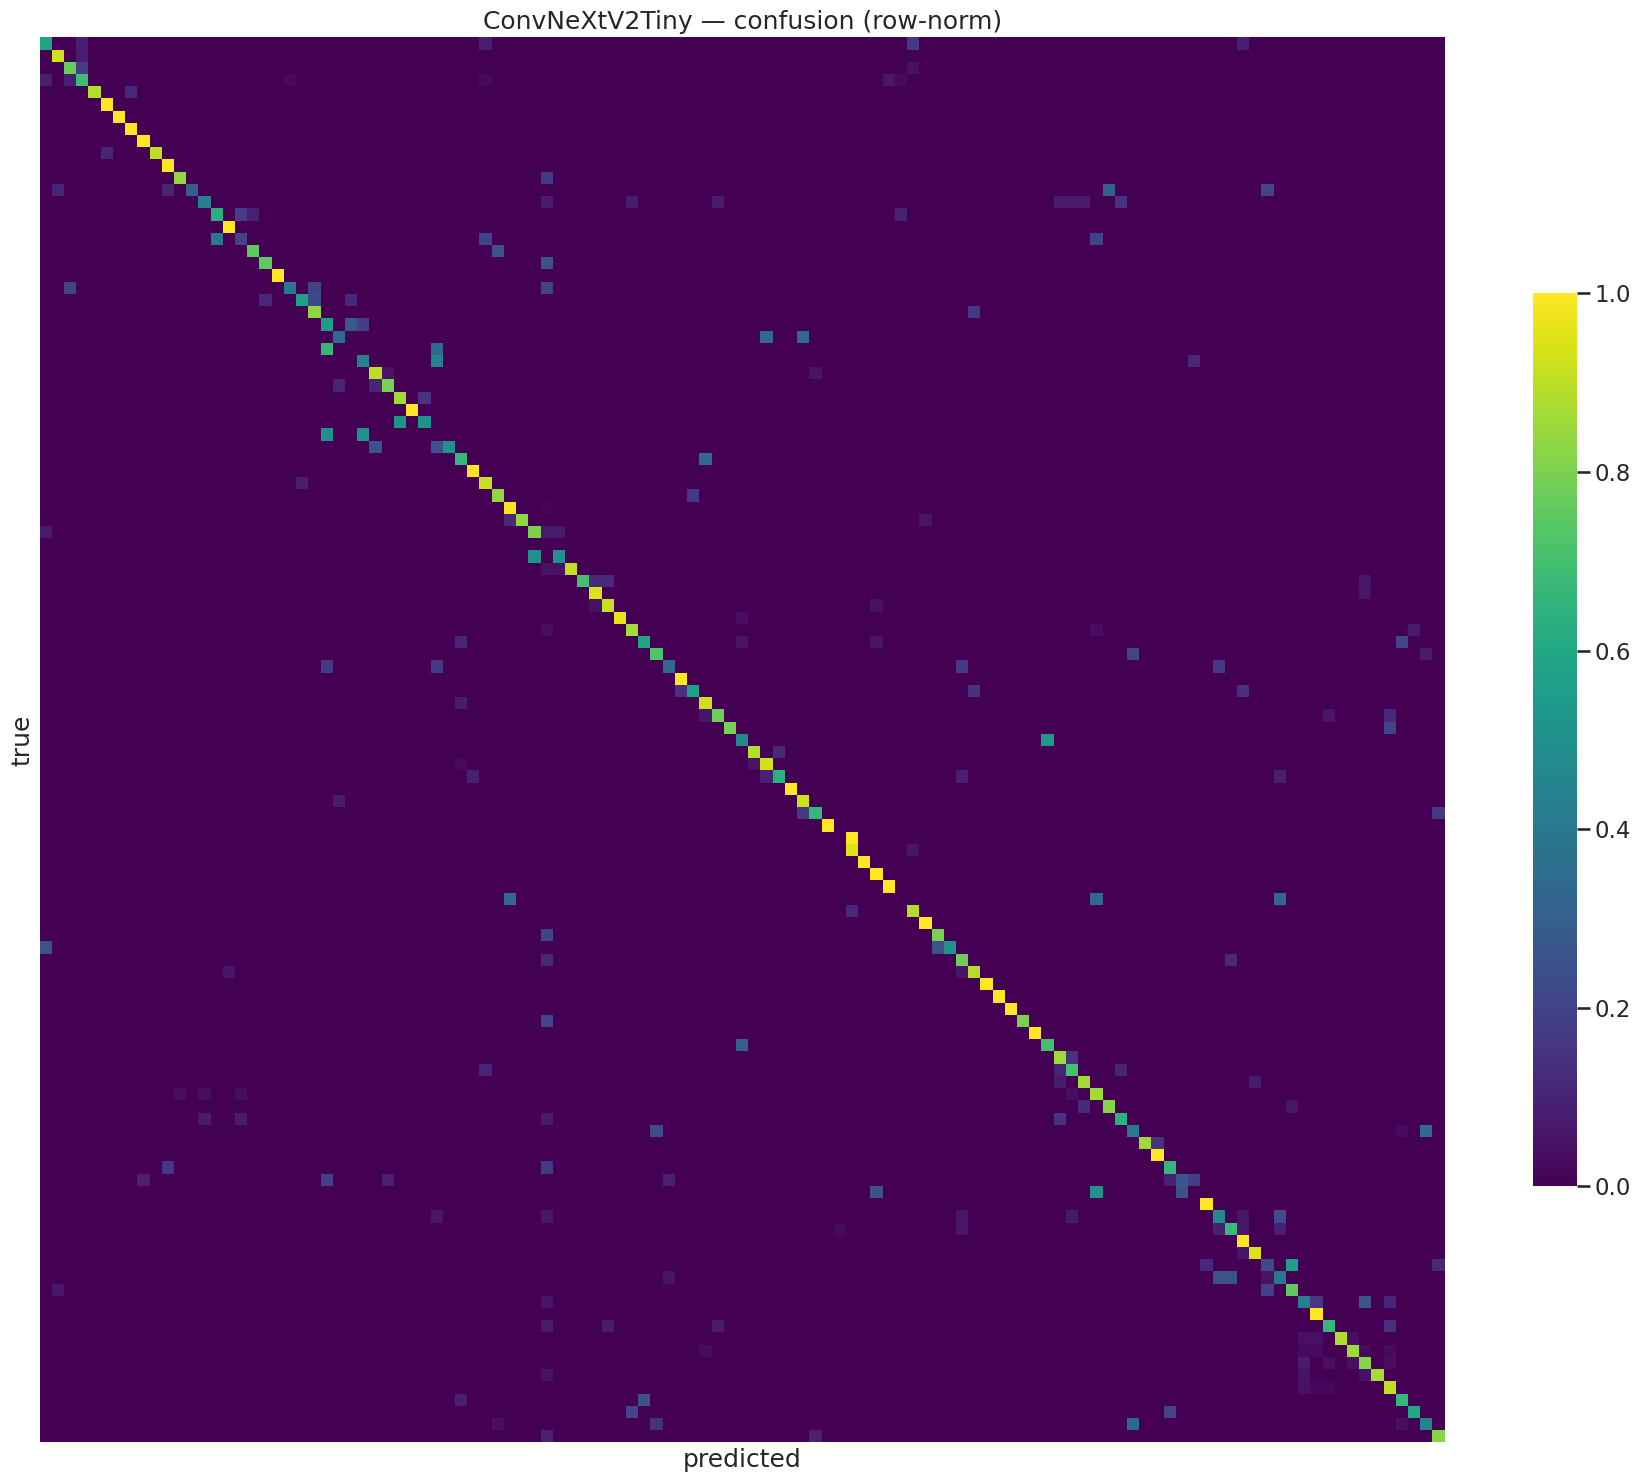

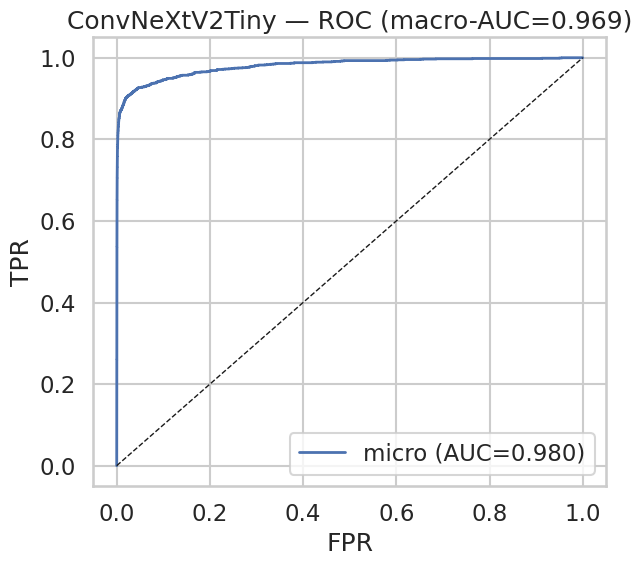

In [8]:
# ============ PER-MODEL FIGURES (inline + saved) ============
ep=range(1,len(hist["train_loss"])+1)
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
ax[0].plot(ep,hist["train_loss"],label="train"); ax[0].plot(ep,hist["val_loss"],label="val"); ax[0].set_title(f"{MODEL_NAME} — loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(ep,hist["train_acc"],label="train"); ax[1].plot(ep,hist["val_acc"],label="val"); ax[1].set_title(f"{MODEL_NAME} — accuracy"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_loss_acc.png",dpi=200,bbox_inches="tight"); plt.show()

cmn=cm.astype(float)/cm.astype(float).sum(1,keepdims=True).clip(min=1); s=max(7,NUM_CLASSES*0.16)
plt.figure(figsize=(s,s)); sns.heatmap(cmn,cmap="viridis",square=True,cbar_kws={"shrink":0.5},
    xticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False, yticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False)
plt.title(f"{MODEL_NAME} — confusion (row-norm)"); plt.xlabel("predicted"); plt.ylabel("true")
plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_confusion.png",dpi=150,bbox_inches="tight"); plt.show()

y_oh=np.eye(NUM_CLASSES)[Y]; fpr,tpr,_=roc_curve(y_oh.ravel(),PR.ravel()); micro=auc(fpr,tpr)
present=[c for c in range(NUM_CLASSES) if (Y==c).sum()>0]
macro=np.mean([auc(*roc_curve((Y==c).astype(int),PR[:,c])[:2]) for c in present])
plt.figure(figsize=(6.5,6)); plt.plot(fpr,tpr,lw=2,label=f"micro (AUC={micro:.3f})"); plt.plot([0,1],[0,1],"k--",lw=1)
plt.title(f"{MODEL_NAME} — ROC (macro-AUC={macro:.3f})"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_roc.png",dpi=200,bbox_inches="tight"); plt.show()

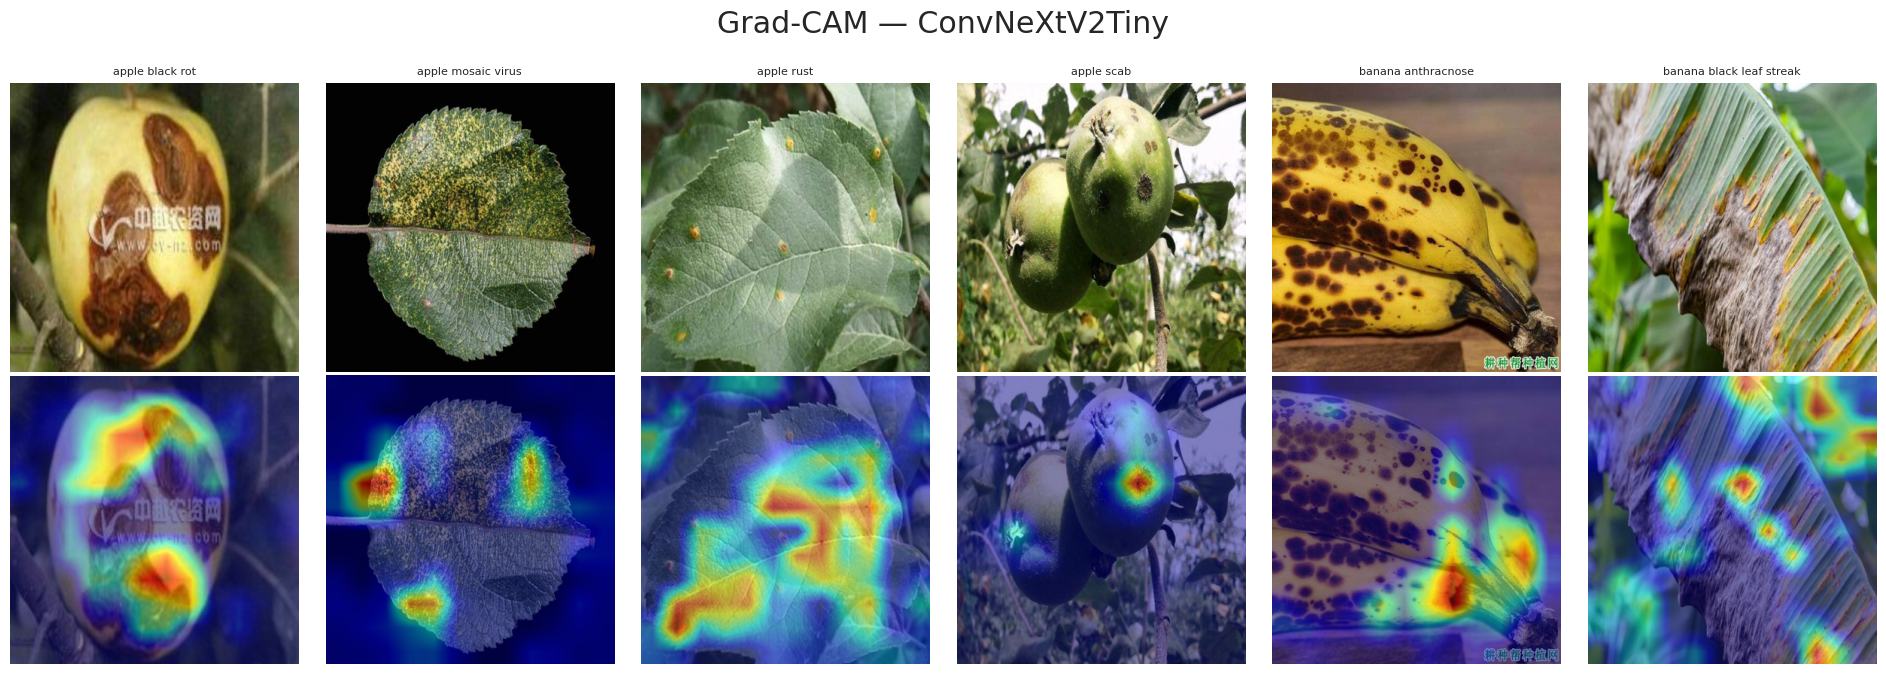

In [9]:
# ============ Grad-CAM (skipped for transformers) ============
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
def tgt(m,name):
    if name=="ResNet50": return [m.layer4[-1]]
    if name=="MobileNetV3Large": return [m.features[-1]]
    if name in ("ConvNeXtV2Tiny",): return [m.stages[-1]]
    if name in ("EfficientNetB0","EfficientNetV2S"): return [m.conv_head]
    if name=="GatedFusionLight": return [m.branch_a.features[-1]]
    return None
_,etf=make_transforms(img_size); tl_=tgt(model,MODEL_NAME)
if tl_ is not None:
    cam=GradCAM(model=model,target_layers=tl_)
    rows=test_df[test_df.plant.isin(FRUIT_HOSTS)].groupby("label").first().reset_index().head(6)
    fig,axes=plt.subplots(2,len(rows),figsize=(3.2*len(rows),7))
    for col,(_,r) in zip(axes.T,rows.iterrows()):
        im=Image.open(r.filepath).convert("RGB").resize((img_size,img_size))
        g=cam(input_tensor=etf(im).unsqueeze(0).to(device))[0]
        col[0].imshow(im); col[0].set_title(r.label,fontsize=8); col[0].axis("off")
        col[1].imshow(show_cam_on_image(np.float32(im)/255.0,g,use_rgb=True)); col[1].axis("off")
    plt.suptitle(f"Grad-CAM — {MODEL_NAME}"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_gradcam.png",dpi=200,bbox_inches="tight"); plt.show()
else:
    print(f"{MODEL_NAME} is a transformer — Grad-CAM skipped (use attention rollout in Stage 4).")